# Vish Dataset v2 — detecção robusta de problemas urbanos

**Projeto acadêmico — IBMEC | Projeto Vish**  
**Tarefa:** detecção de objetos com YOLO26, transfer learning e avaliação sem vazamento de dados.

Este notebook substitui a prova de conceito anterior. A meta não é apenas obter um mAP alto, mas construir um experimento reproduzível e capaz de generalizar para fotografias reais de celular em ruas brasileiras.

Ao final, o notebook permite enviar uma fotografia e visualizar **caixa, classe e confiança** de cada problema detectado.

> Execute em **Ambiente de execução → Alterar tipo de ambiente → GPU**. Para o perfil sério, recomenda-se A100/L4; o código escolhe automaticamente `yolo26m.pt` em GPUs maiores e `yolo26s.pt` em GPUs menores.

> **Correção v2.1:** o importador COCO agora resolve o caminho relativo completo das imagens (incluindo pastas `batch_*` do TACO). A deduplicação também protege arquivos ainda referenciados pelo manifesto. Isso corrige labels órfãos causados por nomes de arquivo repetidos entre lotes.

## 1. Problema de pesquisa e hipótese

**Pergunta:** um detector treinado com bases especializadas, negativos urbanos difíceis, deduplicação e separação por origem consegue reconhecer problemas urbanos em imagens reais com menos falsos positivos que o pipeline v1?

**Hipótese:** a qualidade do conjunto de dados e do protocolo de avaliação terá mais impacto que simplesmente aumentar o número de épocas. O v2 ataca especificamente:

- buracos não detectados;
- pessoas, carros, sombras e tampas de bueiro marcados como problemas;
- classes amplas demais, como “danos elétricos” misturando poste e fio;
- imagens quase idênticas em treino e validação;
- uso de datasets de classificação como se tivessem bounding boxes;
- treino de classes sem quantidade mínima de exemplos.

## 2. Taxonomia do MVP

| ID | Classe | Definição operacional | Não inclui |
|---:|---|---|---|
| 0 | `pothole` | cavidade/depressão localizada com perda de material do pavimento | sombra, poça, remendo ou tampa de bueiro |
| 1 | `garbage` | lixo/resíduo descartado ou acumulado em via/calçada | lixeira fechada e corretamente posicionada |
| 2 | `dangerous_wire` | fio/cabo caído, baixo, solto, rompido ou em situação visivelmente perigosa | fio aéreo normal; poste danificado sem fio perigoso |
| 3 | `damaged_road` | trincas e deterioração relevante da superfície viária | buraco, que possui classe própria |
| 4 | `flooding` | alagamento/inundação cobrindo parte relevante da via | poça pequena e reflexos |

### Por que somente cinco classes?

O primeiro modelo precisa dominar as classes centrais do produto. Adicionar placa, árvore, grafite, animal morto e estacionamento ilegal com poucos rótulos tornaria o diagnóstico dos erros mais difícil e consumiria capacidade do modelo. Novas classes devem entrar apenas quando passarem pelo mesmo gate de cobertura e qualidade.

## 3. Datasets selecionados e como serão usados

| Fonte | Domínio e tamanho | Anotação | Uso no Vish v2 | Licença / link |
|---|---|---|---|---|
| **RDD2022** | 47.420 imagens, seis países | Pascal VOC; D00/D10/D20/D40 | fonte principal de `pothole` e `damaged_road`; download oficial por país | CC BY-SA 4.0; [repositório oficial](https://github.com/sekilab/RoadDamageDetector) |
| **Cracks and Potholes / DNIT 🇧🇷** | 2.235 imagens de ES, RS e DF | máscaras de road/crack/pothole | reforço brasileiro de `pothole`; máscaras viram caixas por componentes conectados | CC BY 4.0; [Mendeley v4](https://data.mendeley.com/datasets/t576ydh9v8/4) |
| **MOMRAH** | dezenas de milhares de imagens de vias públicas | caixas e rótulos; pothole/sidewalk/barrier | reforço opcional de `pothole`; apenas anotações de detecção revisadas | CC BY 4.0; [Mendeley v5](https://data.mendeley.com/datasets/bb7b8vtwry/5) |
| **pLitterStreet** | mais de 13 mil imagens street-level | COCO, totalmente anotado | fonte principal de `garbage` em ruas reais | verificar termos do registro; [Zenodo 8288500](https://zenodo.org/records/8288500) |
| **TACO** | ~1.500 imagens, 4.784 anotações oficiais | COCO/segmentação | complemento de `garbage`; todas as subclasses colapsam em uma classe | imagens com licenças individuais; [GitHub oficial](https://github.com/pedropro/TACO) |
| **WasteInsight 🇧🇷** | 447 imagens de sacos de lixo | bounding boxes | reforço brasileiro de `garbage` | CC BY 4.0; [Mendeley](https://data.mendeley.com/datasets/p8n7nbxyw3/1) |
| **QR4Change** | 2.966 imagens de buraco e 1.971 de lixo | classificação binária | **somente negativos** (`plain road`, `non-garbage`) no detector; positivos sem caixa não entram | CC BY 4.0; [Mendeley v2](https://data.mendeley.com/datasets/zndzygc3p3/2) |
| **Tree–Wires 🇧🇷** | 1.001 imagens de SP e Porto Alegre | classificação de contato árvore–fio | contexto/benchmark auxiliar; não vira caixa automaticamente | [repositório e paper](https://github.com/arturandre/tree-wires) |
| **Wire Detection (AirLab)** | fios com rótulos por pixel, majoritariamente inspeção aérea/sintético | segmentação | apoio para entender “fio”, não prova perigo em rua | [página oficial](https://theairlab.org/wire-detection/) |
| **Dados Vish de fios 🇧🇷** | fotos próprias e revisadas | YOLO bounding boxes | **fonte obrigatória** de `dangerous_wire` para o perfil sério | licença/proveniência definida pelo projeto |
| **Flood Dataset-1** | coleção urbana com negativos e níveis de submersão | COCO pixel-level; 45 classes | somente a classe geral `Flood` vira `flooding`; caixas auxiliares de pessoa/carro/bicicleta são ignoradas | CC BY 4.0; [Mendeley v3](https://data.mendeley.com/datasets/px48m7vwvf/3) |

### Decisões metodológicas importantes

- O RDD2022 oficial continua sendo o benchmark central de dano viário; D40 vira `pothole`, enquanto D00/D10/D20 viram `damaged_road`.
- O pLitterStreet substitui o TACO como base principal de lixo porque tem mais de 13 mil imagens capturadas por câmeras veiculares voltadas para laterais de ruas.
- QR4Change é útil para falsos positivos, mas seus positivos são rótulos de imagem inteira. Sem caixas, **não podem** ser convertidos honestamente em detecção.
- Não existe hoje uma grande base pública perfeitamente alinhada a “fio solto/perigoso em rua brasileira”. Por isso, o perfil sério exige dados próprios/revisados e falha antes do treino se a cobertura for insuficiente.

## 4. Licenças, limitações e risco de domínio

1. **Licenças não são equivalentes.** RDD2022 é ShareAlike; TACO possui licenças por imagem; bases espelhadas em Kaggle/Roboflow podem ter proveniência incompleta. Verifique novamente antes de redistribuir ou usar comercialmente.
2. **Contexto geográfico:** a maior parte dos dados é internacional. O teste final deve conter fotos brasileiras de celular, nunca usadas no treino.
3. **Fio visível não significa fio perigoso.** Imagens de transmissão aérea não devem receber automaticamente o rótulo `dangerous_wire`.
4. **Caixa derivada de máscara:** no DNIT, cada componente conectado da máscara de buraco vira uma caixa; áreas mínimas filtram ruído.
5. **Negativo não significa “sem nada”.** Pessoas, carros, motos, sombras, poças, bueiros, folhas, postes/fios normais e ruas limpas são negativos difíceis valiosos.
6. **Não há promessa de produção:** o notebook gera um experimento acadêmico auditável. Validação em campo e monitoramento contínuo ainda são necessários.

## 5. Protocolo experimental

1. Download com barra de progresso, retomada e cache no Google Drive.
2. Conversão VOC/COCO/YOLO/máscaras para um único YOLO Detection.
3. Manifesto de proveniência por imagem.
4. Remoção de duplicatas exatas e por hash perceptual.
5. Separação por fonte/grupo sequencial, evitando frames vizinhos em splits diferentes.
6. Auditoria de labels, cobertura e vazamento.
7. EDA e inspeção visual antes do treino.
8. Transfer learning com YOLO26 em 960 px.
9. Precision, Recall, mAP50 e mAP50–95 por classe.
10. Teste dedicado em hard negatives e imagens brasileiras.
11. Upload de foto real e inferência com limiar por classe.

In [ ]:
# Instalação. Reiniciar o runtime normalmente não é necessário.
!pip -q install -U ultralytics kagglehub pycocotools imagehash pyyaml tqdm seaborn
!apt-get -qq update && apt-get -qq install -y aria2 > /dev/null

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)


In [ ]:
from __future__ import annotations

import re, json, math, random, hashlib, shutil, subprocess, zipfile
import xml.etree.ElementTree as ET
from collections import Counter, defaultdict
from pathlib import Path

import cv2
import imagehash
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from IPython.display import display
from PIL import Image, ImageDraw
from tqdm.auto import tqdm

from google.colab import drive, files
from ultralytics import YOLO

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("PyTorch:", torch.__version__)
print("CUDA disponível:", torch.cuda.is_available())

PyTorch: 2.11.0+cu128
CUDA disponível: True


In [ ]:
# =========================
# CONFIGURAÇÃO CENTRAL
# =========================

# "smoke" valida o pipeline; "serious" executa o experimento acadêmico completo.
PROFILE = "smoke"

VISH_CLASSES = ["pothole", "garbage", "dangerous_wire", "damaged_road", "flooding"]
CLASS_TO_ID = {name: i for i, name in enumerate(VISH_CLASSES)}
ID_TO_CLASS = {i: name for name, i in CLASS_TO_ID.items()}

# Fontes automáticas
USE_RDD2022 = True
USE_PLITTERSTREET = (PROFILE == "smoke")       # 13,7 GB; download direto e retomável
USE_TACO = True                                  # complemento pequeno de lixo

# Fontes manuais/Drive (processadas automaticamente quando presentes)
USE_DNIT_BR = True
USE_MOMRAH = True
USE_WASTEINSIGHT_BR = True
USE_QR4CHANGE_NEGATIVES = True
USE_CUSTOM_WIRES_BR = True
USE_FLOOD_DATA = True
USE_CUSTOM_HARD_NEGATIVES = True

# Urban Issues é uma fonte fraca/agregada para fios. Deixe False no experimento principal.
USE_URBAN_ISSUES_AUX = False

# Países escolhidos evitam o arquivo da Noruega (~9,9 GB) e ainda dão diversidade.
RDD_COUNTRIES = ["India", "Japan", "Czech", "United_States", "China_MotorBike", "China_Drone"]

if PROFILE == "smoke":
    MAX_IMAGES_PER_SOURCE = 500
    EPOCHS = 10
    IMG_SIZE = 640
    STRICT_COVERAGE_GATE = False
else:
    MAX_IMAGES_PER_SOURCE = None
    EPOCHS = 100
    IMG_SIZE = 960
    STRICT_COVERAGE_GATE = True

# Teste brasileiro próprio deve permanecer isolado. Se vazio, o notebook avisa.
CUSTOM_TEST_IS_NEVER_TRAINED = True

print("Perfil:", PROFILE)
print("Classes:", CLASS_TO_ID)

Perfil: smoke
Classes: {'pothole': 0, 'garbage': 1, 'dangerous_wire': 2, 'damaged_road': 3, 'flooding': 4}


In [ ]:
drive.mount("/content/drive")

PROJECT_ROOT = Path("/content/drive/MyDrive/Vish/v2")
RAW_ROOT = PROJECT_ROOT / "raw"
MANUAL_ROOT = PROJECT_ROOT / "manual_sources"
UNIFIED_ROOT = PROJECT_ROOT / "dataset_yolo"
ARTIFACT_ROOT = PROJECT_ROOT / "artifacts"
RUNS_ROOT = PROJECT_ROOT / "runs"

for root in [RAW_ROOT, MANUAL_ROOT, UNIFIED_ROOT, ARTIFACT_ROOT, RUNS_ROOT]:
    root.mkdir(parents=True, exist_ok=True)

for split in ["train", "val", "test"]:
    (UNIFIED_ROOT / "images" / split).mkdir(parents=True, exist_ok=True)
    (UNIFIED_ROOT / "labels" / split).mkdir(parents=True, exist_ok=True)

print("Projeto:", PROJECT_ROOT)
print("Fontes manuais:", MANUAL_ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Projeto: /content/drive/MyDrive/Vish/v2
Fontes manuais: /content/drive/MyDrive/Vish/v2/manual_sources


## 6. Estrutura esperada para fontes manuais

Coloque e extraia os datasets abaixo no Google Drive. O notebook procura arquivos recursivamente, portanto pequenas diferenças de subpastas são toleradas.

```text
MyDrive/Vish/v2/manual_sources/
├── dnit_br/                    # RAW + POTHOLE/máscaras PNG
├── momrah_yolo/                # data.yaml + images/labels
├── wasteinsight_yolo/          # data.yaml + images/labels
├── qr4change/                  # pastas plain/non-garbage
├── dangerous_wire_yolo/        # data.yaml + images/labels REVISADOS
├── flood_yolo_or_coco/         # data.yaml ou COCO JSON
├── hard_negatives/             # imagens urbanas sem problema Vish
└── vish_br_test/               # images/labels; jamais entra no treino
```

Para `dangerous_wire_yolo`, o `data.yaml` deve nomear classes de forma inequívoca, como `dangerous_wire`, `fallen_wire`, `loose_wire`, `hanging_wire` ou `slack_wire`. Rótulos genéricos como `wire`, `cable` ou `pole` são rejeitados por padrão.

In [ ]:
SOURCE_REGISTRY = pd.DataFrame([
    {"source": "RDD2022", "task": "VOC detection", "classes": "pothole, damaged_road", "license": "CC BY-SA 4.0", "url": "https://github.com/sekilab/RoadDamageDetector", "enabled": USE_RDD2022},
    {"source": "DNIT_BR", "task": "semantic masks", "classes": "pothole", "license": "CC BY 4.0", "url": "https://data.mendeley.com/datasets/t576ydh9v8/4", "enabled": USE_DNIT_BR},
    {"source": "MOMRAH", "task": "detection", "classes": "pothole", "license": "CC BY 4.0", "url": "https://data.mendeley.com/datasets/bb7b8vtwry/5", "enabled": USE_MOMRAH},
    {"source": "pLitterStreet", "task": "COCO detection", "classes": "garbage", "license": "ver registro", "url": "https://zenodo.org/records/8288500", "enabled": USE_PLITTERSTREET},
    {"source": "TACO", "task": "COCO instance segmentation", "classes": "garbage", "license": "por imagem", "url": "https://github.com/pedropro/TACO", "enabled": USE_TACO},
    {"source": "WasteInsight_BR", "task": "detection", "classes": "garbage", "license": "CC BY 4.0", "url": "https://data.mendeley.com/datasets/p8n7nbxyw3/1", "enabled": USE_WASTEINSIGHT_BR},
    {"source": "QR4Change", "task": "classification", "classes": "hard negatives", "license": "CC BY 4.0", "url": "https://data.mendeley.com/datasets/zndzygc3p3/2", "enabled": USE_QR4CHANGE_NEGATIVES},
    {"source": "Vish_Wires_BR", "task": "YOLO detection", "classes": "dangerous_wire", "license": "projeto", "url": "dados próprios/revisados", "enabled": USE_CUSTOM_WIRES_BR},
    {"source": "Flood_Dataset_1", "task": "COCO pixel-level", "classes": "flooding (classe geral)", "license": "CC BY 4.0", "url": "https://data.mendeley.com/datasets/px48m7vwvf/3", "enabled": USE_FLOOD_DATA},
    {"source": "HardNegatives", "task": "negative images", "classes": "none", "license": "registrar", "url": "dados próprios/abertos", "enabled": USE_CUSTOM_HARD_NEGATIVES},
])
display(SOURCE_REGISTRY)
SOURCE_REGISTRY.to_csv(ARTIFACT_ROOT / "source_registry.csv", index=False)

,source,task,classes,license,url,enabled
0,RDD2022,VOC detection,"pothole, damaged_road",CC BY-SA 4.0,https://github.com/sekilab/RoadDamageDetector,True
1,DNIT_BR,semantic masks,pothole,CC BY 4.0,https://data.mendeley.com/datasets/t576ydh9v8/4,True
2,MOMRAH,detection,pothole,CC BY 4.0,https://data.mendeley.com/datasets/bb7b8vtwry/5,True
3,pLitterStreet,COCO detection,garbage,ver registro,https://zenodo.org/records/8288500,True
4,TACO,COCO instance segmentation,garbage,por imagem,https://github.com/pedropro/TACO,True
5,WasteInsight_BR,detection,garbage,CC BY 4.0,https://data.mendeley.com/datasets/p8n7nbxyw3/1,True
6,QR4Change,classification,hard negatives,CC BY 4.0,https://data.mendeley.com/datasets/zndzygc3p3/2,True
7,Vish_Wires_BR,YOLO detection,dangerous_wire,projeto,dados próprios/revisados,True
8,Flood_Dataset_1,COCO pixel-level,flooding (classe geral),CC BY 4.0,https://data.mendeley.com/datasets/px48m7vwvf/3,True
9,HardNegatives,negative images,none,registrar,dados próprios/abertos,True


In [ ]:
# Diagnóstico de recursos antes de downloads longos.
usage = shutil.disk_usage("/content")
print(f"Disco livre: {usage.free / 2**30:.1f} GB")

if torch.cuda.is_available():
    gpu = torch.cuda.get_device_properties(0)
    gpu_gb = gpu.total_memory / 2**30
    print("GPU:", gpu.name, f"({gpu_gb:.1f} GB)")
else:
    gpu_gb = 0
    print("⚠️ Ative GPU antes do treinamento.")

estimated_download_gb = 18 if USE_PLITTERSTREET else 4
if usage.free / 2**30 < estimated_download_gb + 15:
    raise RuntimeError("Espaço insuficiente para baixar, extrair e preparar os datasets selecionados.")

Disco livre: 62.7 GB
GPU: Tesla T4 (14.6 GB)


In [ ]:
# Helpers: download retomável e extração idempotente.

def run(cmd):
    print("$", " ".join(map(str, cmd)))
    subprocess.run(list(map(str, cmd)), check=True)


def download_with_resume(url: str, destination: Path):
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    complete = destination.exists() and destination.stat().st_size > 0
    if destination.suffix.lower() == ".zip" and complete:
        complete = zipfile.is_zipfile(destination)
    if complete and not Path(str(destination) + ".aria2").exists():
        print("Cache:", destination.name, f"({destination.stat().st_size / 2**20:.1f} MB)")
        return destination
    # aria2 mostra progresso e permite retomar após desconexão do Colab.
    run(["aria2c", "-c", "-x", "8", "-s", "8", "--file-allocation=none", "-d", destination.parent, "-o", destination.name, url])
    return destination


def extract_zip_once(zip_path: Path, destination: Path):
    marker = Path(destination) / ".extracted_ok"
    if marker.exists():
        print("Extração em cache:", destination)
        return Path(destination)
    Path(destination).mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path) as zf:
        for member in tqdm(zf.infolist(), desc=f"Extraindo {Path(zip_path).name}"):
            zf.extract(member, destination)
    marker.touch()
    return Path(destination)

In [ ]:
# RDD2022 — download oficial por país.
RDD_BASE = "https://bigdatacup.s3.ap-northeast-1.amazonaws.com/2022/CRDDC2022/RDD2022/Country_Specific_Data_CRDDC2022"
RDD_ROOT = RAW_ROOT / "rdd2022"

if USE_RDD2022:
    for country in RDD_COUNTRIES:
        archive = RAW_ROOT / "archives" / f"RDD2022_{country}.zip"
        url = f"{RDD_BASE}/RDD2022_{country}.zip"
        try:
            download_with_resume(url, archive)
            extract_zip_once(archive, RDD_ROOT / country)
        except Exception as exc:
            print(f"⚠️ Falha no download oficial de {country}: {exc}")
            print("Baixe pelo repositório oficial e coloque o ZIP em:", archive)
else:
    print("RDD2022 desabilitado.")

$ aria2c -c -x 8 -s 8 --file-allocation=none -d /content/drive/MyDrive/Vish/v2/raw/archives -o RDD2022_India.zip https://bigdatacup.s3.ap-northeast-1.amazonaws.com/2022/CRDDC2022/RDD2022/Country_Specific_Data_CRDDC2022/RDD2022_India.zip
⚠️ Falha no download oficial de India: Command '['aria2c', '-c', '-x', '8', '-s', '8', '--file-allocation=none', '-d', '/content/drive/MyDrive/Vish/v2/raw/archives', '-o', 'RDD2022_India.zip', 'https://bigdatacup.s3.ap-northeast-1.amazonaws.com/2022/CRDDC2022/RDD2022/Country_Specific_Data_CRDDC2022/RDD2022_India.zip']' returned non-zero exit status 22.
Baixe pelo repositório oficial e coloque o ZIP em: /content/drive/MyDrive/Vish/v2/raw/archives/RDD2022_India.zip
$ aria2c -c -x 8 -s 8 --file-allocation=none -d /content/drive/MyDrive/Vish/v2/raw/archives -o RDD2022_Japan.zip https://bigdatacup.s3.ap-northeast-1.amazonaws.com/2022/CRDDC2022/RDD2022/Country_Specific_Data_CRDDC2022/RDD2022_Japan.zip
⚠️ Falha no download oficial de Japan: Command '['aria2c',

In [ ]:
# pLitterStreet — 13,7 GB. O arquivo é grande, mas vem empacotado e o download é retomável.
PLITTER_ROOT = RAW_ROOT / "plitterstreet"

if USE_PLITTERSTREET:
    ann_zip = download_with_resume(
        "https://zenodo.org/records/8288500/files/annotations.zip?download=1",
        RAW_ROOT / "archives" / "plitter_annotations.zip",
    )
    img_zip = download_with_resume(
        "https://zenodo.org/records/8288500/files/images.zip?download=1",
        RAW_ROOT / "archives" / "plitter_images.zip",
    )
    extract_zip_once(ann_zip, PLITTER_ROOT)
    extract_zip_once(img_zip, PLITTER_ROOT)
else:
    print("pLitterStreet desabilitado. No perfil sério ele deve ser a principal fonte de garbage.")

Cache: plitter_annotations.zip (8.4 MB)
Cache: plitter_images.zip (13092.6 MB)
Extração em cache: /content/drive/MyDrive/Vish/v2/raw/plitterstreet
Extração em cache: /content/drive/MyDrive/Vish/v2/raw/plitterstreet


In [ ]:
# TACO — espelho empacotado no Kaggle para evitar o downloader oficial imagem por imagem.
TACO_ROOT = None
if USE_TACO:
    import kagglehub
    try:
        TACO_ROOT = Path(kagglehub.dataset_download("kneroma/tacotrashdataset"))
        print("TACO:", TACO_ROOT)
    except Exception as exc:
        print("⚠️ TACO não baixado:", exc)
        print("O treinamento pode continuar com pLitterStreet, mas registre a ausência no relatório.")

Using Colab cache for faster access to the 'tacotrashdataset' dataset.
TACO: /kaggle/input/tacotrashdataset


In [ ]:
# =========================
# FUNÇÕES DE NORMALIZAÇÃO
# =========================

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
manifest_rows = []


def list_images(root: Path):
    root = Path(root)
    return sorted(p for p in root.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTS)


def stable_split(source: str, group: str, test_allowed=True):
    # Split determinístico por grupo; imagens do mesmo grupo nunca se separam.
    value = int(hashlib.sha1(f"{SEED}:{source}:{group}".encode()).hexdigest()[:8], 16) % 100
    if value < 80:
        return "train"
    if value < 90:
        return "val"
    return "test" if test_allowed else "val"


def sequence_group(path: Path, block=20):
    # Agrupa frames vizinhos pelo último número do nome, reduzindo leakage temporal.
    nums = re.findall(r"\d+", Path(path).stem)
    if nums:
        n = int(nums[-1])
        prefix = Path(path).stem[: max(0, Path(path).stem.rfind(nums[-1]))]
        return f"{Path(path).parent.name}:{prefix}:{n // block}"
    return f"{Path(path).parent.name}:{Path(path).stem}"


def image_destination(source, image_path, split):
    token = hashlib.sha1(f"{source}:{image_path}".encode()).hexdigest()[:14]
    ext = image_path.suffix.lower() if image_path.suffix.lower() in IMAGE_EXTS else ".jpg"
    name = f"{source}_{token}{ext}"
    return UNIFIED_ROOT / "images" / split / name


def write_sample(source, image_path, split, yolo_lines, group, original_split=None, is_negative=False):
    dest_img = image_destination(source, Path(image_path), split)
    dest_lbl = UNIFIED_ROOT / "labels" / split / f"{dest_img.stem}.txt"
    if not dest_img.exists():
        shutil.copy2(image_path, dest_img)
    dest_lbl.write_text("\n".join(yolo_lines), encoding="utf-8")
    manifest_rows.append({
        "file": dest_img.name,
        "image_path": str(dest_img),
        "label_path": str(dest_lbl),
        "split": split,
        "source": source,
        "source_file": str(image_path),
        "group": f"{source}:{group}",
        "original_split": original_split,
        "num_boxes": len(yolo_lines),
        "is_negative": bool(is_negative or len(yolo_lines) == 0),
    })


def xyxy_to_yolo(x1, y1, x2, y2, width, height, class_id):
    x1, x2 = sorted((max(0.0, x1), min(float(width), x2)))
    y1, y2 = sorted((max(0.0, y1), min(float(height), y2)))
    bw, bh = x2 - x1, y2 - y1
    if bw < 2 or bh < 2 or width <= 0 or height <= 0:
        return None
    xc, yc = x1 + bw / 2, y1 + bh / 2
    return f"{class_id} {xc/width:.6f} {yc/height:.6f} {bw/width:.6f} {bh/height:.6f}"

In [ ]:
def import_rdd2022(root: Path, max_images=None):
    xmls = sorted(Path(root).rglob("*.xml"))
    if max_images:
        random.Random(SEED).shuffle(xmls)
        xmls = xmls[:max_images]
    imported = 0
    for xml_path in tqdm(xmls, desc="RDD2022 VOC → Vish"):
        try:
            tree = ET.parse(xml_path)
            xroot = tree.getroot()
            filename = xroot.findtext("filename")
            width = int(float(xroot.findtext("size/width")))
            height = int(float(xroot.findtext("size/height")))
            candidates = []
            if filename:
                candidates.extend(xml_path.parents[i] / "images" / filename for i in range(min(4, len(xml_path.parents))))
            candidates.extend(xml_path.parents[i] / "images" / f"{xml_path.stem}.jpg" for i in range(min(4, len(xml_path.parents))))
            image_path = next((p for p in candidates if p.exists()), None)
            if image_path is None:
                found = list(Path(root).rglob(f"{xml_path.stem}.jpg"))
                image_path = found[0] if found else None
            if image_path is None:
                continue

            lines = []
            for obj in xroot.findall("object"):
                label = (obj.findtext("name") or "").strip().upper()
                target = "pothole" if label == "D40" else "damaged_road" if label in {"D00", "D10", "D20"} else None
                if target is None:
                    continue
                box = obj.find("bndbox")
                line = xyxy_to_yolo(
                    float(box.findtext("xmin")), float(box.findtext("ymin")),
                    float(box.findtext("xmax")), float(box.findtext("ymax")),
                    width, height, CLASS_TO_ID[target],
                )
                if line:
                    lines.append(line)

            group = sequence_group(image_path)
            # Frames sem dano anotado são negativos urbanos úteis.
            split = stable_split("rdd2022", group)
            write_sample("rdd2022", image_path, split, lines, group, original_split="train")
            imported += 1
        except Exception as exc:
            print("XML ignorado:", xml_path, exc)
    return imported

In [ ]:
def build_coco_image_index(root: Path):
    """Indexa imagens por nome-base sem perder colisões entre pastas batch_*.

    Um dicionário simples {nome: caminho} é incorreto para COCO/TACO porque nomes como
    000006.jpg podem existir em mais de um lote. Por isso cada nome aponta para uma lista.
    """
    index = defaultdict(list)
    for path in list_images(root):
        index[path.name.lower()].append(path)
    return index


def _common_suffix_parts(path_a: Path, path_b: Path):
    a = [part.lower() for part in path_a.parts]
    b = [part.lower() for part in path_b.parts]
    score = 0
    for left, right in zip(reversed(a), reversed(b)):
        if left != right:
            break
        score += 1
    return score


def find_image_for_coco(root: Path, file_name: str, image_index=None, annotation_dir=None):
    """Resolve uma imagem COCO priorizando o caminho relativo completo.

    Só usa o nome-base quando ele é único. Se houver colisão, compara os sufixos
    (por exemplo batch_6/000006.jpg) e rejeita resultados ainda ambíguos.
    """
    root = Path(root)
    relative = Path(str(file_name).replace("\\", "/").lstrip("./"))

    search_bases = []
    if annotation_dir is not None:
        search_bases.append(Path(annotation_dir))
    search_bases.append(root)

    for base in search_bases:
        candidate = base / relative
        if candidate.is_file():
            return candidate

    if image_index is None:
        image_index = build_coco_image_index(root)

    candidates = image_index.get(relative.name.lower(), [])
    if len(candidates) == 1:
        return candidates[0]
    if not candidates:
        return None

    scored = sorted(
        ((_common_suffix_parts(candidate, relative), candidate) for candidate in candidates),
        key=lambda item: item[0],
        reverse=True,
    )
    best_score = scored[0][0]
    best = [candidate for score, candidate in scored if score == best_score]

    # Score 1 significa que apenas o nome-base coincidiu; isso não resolve a colisão.
    return best[0] if best_score >= 2 and len(best) == 1 else None


def import_coco_collapsed(root: Path, source: str, target_class: str, json_hint=None, max_images=None, category_allowlist=None):
    root = Path(root)
    jsons = sorted(root.rglob("*.json"))
    if json_hint:
        exact = [p for p in jsons if p.name.lower() == json_hint.lower()]
        hinted = exact or [p for p in jsons if json_hint.lower() in p.name.lower()]
        jsons = hinted or jsons
    if not jsons:
        print(f"[{source}] nenhum JSON COCO encontrado")
        return 0
    ann_path = max(jsons, key=lambda p: p.stat().st_size)
    data = json.loads(ann_path.read_text(encoding="utf-8", errors="ignore"))
    if not {"images", "annotations"}.issubset(data):
        print(f"[{source}] JSON não parece COCO:", ann_path)
        return 0
    category_names = {int(c["id"]): normalize_name(c.get("name", "")) for c in data.get("categories", [])}
    allowed = {normalize_name(x) for x in category_allowlist} if category_allowlist else None
    anns = defaultdict(list)
    for ann in data["annotations"]:
        if ann.get("iscrowd", 0):
            continue
        if allowed is not None and category_names.get(int(ann.get("category_id", -1))) not in allowed:
            continue
        anns[ann["image_id"]].append(ann)
    images = list(data["images"])

    # Mantém todas as colisões de nome-base e resolve pelo caminho relativo do COCO.
    image_index = build_coco_image_index(root)
    random.Random(SEED).shuffle(images)
    if max_images:
        images = images[:max_images]

    imported = 0
    unresolved = []
    repeated_source_files = 0
    seen_source_files = set()
    for item in tqdm(images, desc=f"{source} COCO → Vish"):
        image_path = find_image_for_coco(
            root,
            item["file_name"],
            image_index=image_index,
            annotation_dir=ann_path.parent,
        )
        if image_path is None:
            unresolved.append(item["file_name"])
            continue

        resolved_key = str(image_path.resolve())
        if resolved_key in seen_source_files:
            repeated_source_files += 1
            continue
        seen_source_files.add(resolved_key)

        width, height = int(item["width"]), int(item["height"])
        lines = []
        for ann in anns.get(item["id"], []):
            x, y, w, h = map(float, ann["bbox"])
            line = xyxy_to_yolo(x, y, x+w, y+h, width, height, CLASS_TO_ID[target_class])
            if line:
                lines.append(line)
        group = sequence_group(image_path)
        split = stable_split(source, group)
        write_sample(source, image_path, split, lines, group)
        imported += 1

    print(f"[{source}] COCO usado:", ann_path)
    print(f"[{source}] imagens importadas: {imported}")
    if unresolved:
        print(f"⚠️ [{source}] imagens não resolvidas/ambíguas: {len(unresolved)}")
        print("Exemplos:", unresolved[:10])
    if repeated_source_files:
        print(f"⚠️ [{source}] referências COCO repetidas ignoradas: {repeated_source_files}")
    return imported


In [ ]:
SAFE_WIRE_LABELS = {
    "dangerous_wire", "fallen_wire", "loose_wire", "hanging_wire", "slack_wire",
    "downed_wire", "broken_wire", "fallen_cable", "loose_cable"
}


def normalize_name(name):
    return re.sub(r"[^a-z0-9]+", "_", str(name).strip().lower()).strip("_")


def yaml_names(cfg):
    names = cfg.get("names", {})
    if isinstance(names, list):
        return {i: v for i, v in enumerate(names)}
    return {int(k): v for k, v in names.items()}


def infer_label_path(img: Path):
    parts = list(img.parts)
    if "images" in parts:
        idx = len(parts) - 1 - parts[::-1].index("images")
        parts[idx] = "labels"
        return Path(*parts).with_suffix(".txt")
    return img.with_suffix(".txt")


def import_yolo_dataset(root: Path, source: str, name_map: dict, strict_wire=False, max_images=None, force_split=None, allow_empty_labels=False):
    root = Path(root)
    yamls = list(root.rglob("*.yaml")) + list(root.rglob("*.yml"))
    if not yamls:
        print(f"[{source}] data.yaml não encontrado em {root}")
        return 0
    yaml_path = next((p for p in yamls if p.name in {"data.yaml", "dataset.yaml"}), yamls[0])
    cfg = yaml.safe_load(yaml_path.read_text(encoding="utf-8", errors="ignore"))
    names = yaml_names(cfg)
    mapping = {}
    for old_id, old_name in names.items():
        normalized = normalize_name(old_name)
        if strict_wire and normalized not in SAFE_WIRE_LABELS:
            continue
        target = name_map.get(normalized)
        if target in CLASS_TO_ID:
            mapping[old_id] = CLASS_TO_ID[target]
    print(f"[{source}] mapeamento:", {names[k]: ID_TO_CLASS[v] for k, v in mapping.items()})
    if not mapping:
        print(f"[{source}] nenhuma classe segura mapeada")
        return 0

    images = list_images(root)
    random.Random(SEED).shuffle(images)
    if max_images:
        images = images[:max_images]
    imported = 0
    for img in tqdm(images, desc=f"{source} YOLO → Vish"):
        old_label = infer_label_path(img)
        if not old_label.exists():
            continue
        lines = []
        for line in old_label.read_text(encoding="utf-8", errors="ignore").splitlines():
            fields = line.split()
            if len(fields) < 5:
                continue
            try:
                old_id = int(float(fields[0]))
            except ValueError:
                continue
            if old_id in mapping:
                fields[0] = str(mapping[old_id])
                lines.append(" ".join(fields[:5]))
        if not lines and not allow_empty_labels:
            continue
        group = sequence_group(img)
        split = force_split or stable_split(source, group)
        write_sample(source, img, split, lines, group)
        imported += 1
    return imported

In [ ]:
def import_dnit_masks(root: Path, max_images=None, min_component_area=80):
    root = Path(root)
    masks = [p for p in root.rglob("*.png") if "pothole" in str(p).lower()]
    random.Random(SEED).shuffle(masks)
    if max_images:
        masks = masks[:max_images]
    imported = 0
    for mask_path in tqdm(masks, desc="DNIT máscaras → Vish"):
        candidates = []
        text = str(mask_path)
        for token in ["POTHOLE", "pothole", "Pothole"]:
            candidates.extend(Path(text.replace(token, raw)) for raw in ["RAW", "raw", "Raw"])
        candidates.extend(mask_path.parent.parent.rglob(f"{mask_path.stem}.*"))
        image_path = next((p for p in candidates if p.exists() and p.suffix.lower() in IMAGE_EXTS and p != mask_path), None)
        if image_path is None:
            continue
        mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
        if mask is None:
            continue
        binary = (mask > 0).astype(np.uint8)
        n, labels, stats, _ = cv2.connectedComponentsWithStats(binary, connectivity=8)
        h, w = binary.shape
        lines = []
        for i in range(1, n):
            x, y, bw, bh, area = stats[i]
            if area < min_component_area:
                continue
            line = xyxy_to_yolo(x, y, x+bw, y+bh, w, h, CLASS_TO_ID["pothole"])
            if line:
                lines.append(line)
        group = sequence_group(image_path)
        split = stable_split("dnit_br", group)
        write_sample("dnit_br", image_path, split, lines, group)
        imported += 1
    return imported


def import_negative_folders(root: Path, source: str, include_tokens=None, max_images=None, force_split=None):
    root = Path(root)
    images = list_images(root) if root.exists() else []
    if include_tokens:
        tokens = [normalize_name(x) for x in include_tokens]
        images = [p for p in images if any(t in normalize_name(str(p.parent)) for t in tokens)]
    random.Random(SEED).shuffle(images)
    if max_images:
        images = images[:max_images]
    for img in tqdm(images, desc=f"{source} negativos"):
        group = sequence_group(img)
        split = force_split or stable_split(source, group)
        write_sample(source, img, split, [], group, is_negative=True)
    return len(images)

In [ ]:
# Limpa apenas a versão unificada, nunca os dados brutos/manuais.
# Ative quando quiser reconstruir o dataset do zero.
REBUILD_UNIFIED = True

if REBUILD_UNIFIED:
    for split in ["train", "val", "test"]:
        for folder in [UNIFIED_ROOT / "images" / split, UNIFIED_ROOT / "labels" / split]:
            for p in folder.iterdir():
                if p.is_file():
                    p.unlink()
    manifest_rows.clear()
    print("Dataset unificado anterior limpo com segurança.")

Dataset unificado anterior limpo com segurança.


In [ ]:
# =========================
# IMPORTAÇÃO DAS FONTES
# =========================
counts = {}

counts["RDD2022"] = import_rdd2022(RDD_ROOT, MAX_IMAGES_PER_SOURCE) if USE_RDD2022 and RDD_ROOT.exists() else 0
counts["pLitterStreet"] = import_coco_collapsed(PLITTER_ROOT, "plitterstreet", "garbage", max_images=MAX_IMAGES_PER_SOURCE) if USE_PLITTERSTREET and PLITTER_ROOT.exists() else 0
counts["TACO"] = import_coco_collapsed(TACO_ROOT, "taco", "garbage", json_hint="annotations.json", max_images=MAX_IMAGES_PER_SOURCE) if USE_TACO and TACO_ROOT else 0

dnit_root = MANUAL_ROOT / "dnit_br"
counts["DNIT_BR"] = import_dnit_masks(dnit_root, MAX_IMAGES_PER_SOURCE) if USE_DNIT_BR and dnit_root.exists() else 0

pothole_map = {"pothole": "pothole", "potholes": "pothole"}
counts["MOMRAH"] = import_yolo_dataset(MANUAL_ROOT / "momrah_yolo", "momrah", pothole_map, max_images=MAX_IMAGES_PER_SOURCE) if USE_MOMRAH and (MANUAL_ROOT / "momrah_yolo").exists() else 0

garbage_map = {k: "garbage" for k in ["garbage", "trash", "litter", "waste", "trash_bag", "garbage_bag"]}
counts["WasteInsight_BR"] = import_yolo_dataset(MANUAL_ROOT / "wasteinsight_yolo", "wasteinsight_br", garbage_map, max_images=MAX_IMAGES_PER_SOURCE) if USE_WASTEINSIGHT_BR and (MANUAL_ROOT / "wasteinsight_yolo").exists() else 0

wire_map = {name: "dangerous_wire" for name in SAFE_WIRE_LABELS}
counts["Vish_Wires_BR"] = import_yolo_dataset(MANUAL_ROOT / "dangerous_wire_yolo", "vish_wires_br", wire_map, strict_wire=True, max_images=MAX_IMAGES_PER_SOURCE) if USE_CUSTOM_WIRES_BR and (MANUAL_ROOT / "dangerous_wire_yolo").exists() else 0

flood_map = {k: "flooding" for k in ["flood", "flooding", "urban_flood", "flooded_road", "waterlogging"]}
flood_root = MANUAL_ROOT / "flood_yolo_or_coco"
counts["Flood"] = 0
if USE_FLOOD_DATA and flood_root.exists():
    if list(flood_root.rglob("*.yaml")) + list(flood_root.rglob("*.yml")):
        counts["Flood"] = import_yolo_dataset(flood_root, "flood", flood_map, max_images=MAX_IMAGES_PER_SOURCE)
    else:
        counts["Flood"] = import_coco_collapsed(
            flood_root, "flood", "flooding", max_images=MAX_IMAGES_PER_SOURCE,
            category_allowlist={"flood", "flooding", "general_flood"},
        )

counts["QR4Change_neg"] = import_negative_folders(
    MANUAL_ROOT / "qr4change", "qr4change_neg",
    include_tokens=["plain", "non_pothole", "no_pothole", "non_garbage", "no_garbage", "clean"],
    max_images=MAX_IMAGES_PER_SOURCE,
) if USE_QR4CHANGE_NEGATIVES else 0

counts["HardNegatives"] = import_negative_folders(
    MANUAL_ROOT / "hard_negatives", "hard_negatives",
    max_images=MAX_IMAGES_PER_SOURCE,
) if USE_CUSTOM_HARD_NEGATIVES else 0

# Teste brasileiro nunca entra em train/val.
test_root = MANUAL_ROOT / "vish_br_test"
test_map = {name: name for name in VISH_CLASSES}
counts["Vish_BR_TEST"] = import_yolo_dataset(
    test_root, "vish_br_test", test_map, max_images=None,
    force_split="test", allow_empty_labels=True,
) if test_root.exists() else 0

display(pd.Series(counts, name="imagens_importadas").to_frame())

plitterstreet COCO → Vish:   0%|          | 0/500 [00:00<?, ?it/s]

[plitterstreet] COCO usado: /content/drive/MyDrive/Vish/v2/raw/plitterstreet/annotations/4_class_splits/annotations_train.json
[plitterstreet] imagens importadas: 0
⚠️ [plitterstreet] imagens não resolvidas/ambíguas: 500
Exemplos: ['Rangsit_2021_GX104613_297.jpg', 'Taladthai_2021_GX014429_190.jpg', 'Chiangrai_2021_GH010115_107.jpg', 'Rangsit_2021_GX114614_283.jpg', 'Chiangrai_2021_GH190122_86_97964.jpg', 'Rangsit_2021_GX204613_108.jpg', 'Rangsit_2021_GX204613_206.jpg', 'Mawanella_2022_GX060155_284.jpg', 'Rangsit_2021_GX014613_215.jpg', 'Chiangrai_2021_GH010123_180.jpg']


taco COCO → Vish:   0%|          | 0/500 [00:00<?, ?it/s]

[taco] COCO usado: /kaggle/input/tacotrashdataset/data/annotations.json
[taco] imagens importadas: 500


qr4change_neg negativos: 0it [00:00, ?it/s]

hard_negatives negativos: 0it [00:00, ?it/s]

,imagens_importadas
RDD2022,0
pLitterStreet,0
TACO,500
DNIT_BR,0
MOMRAH,0
WasteInsight_BR,0
Vish_Wires_BR,0
Flood,0
QR4Change_neg,0
HardNegatives,0


### Observação sobre a célula anterior

“Importada” significa que a imagem passou pela conversão e ganhou label YOLO compatível — não que a qualidade esteja automaticamente aprovada. As próximas células removem duplicatas, auditam coordenadas, medem cobertura e mostram amostras.

In [ ]:
manifest = pd.DataFrame(manifest_rows)
if manifest.empty:
    raise RuntimeError("Nenhuma imagem foi importada. Revise downloads e caminhos das fontes.")


def file_md5(path, chunk=1024*1024):
    h = hashlib.md5()
    with open(path, "rb") as f:
        while data := f.read(chunk):
            h.update(data)
    return h.hexdigest()


def perceptual_hash(path):
    try:
        with Image.open(path) as im:
            return str(imagehash.phash(im.convert("RGB")))
    except Exception:
        return None


hash_cache_path = ARTIFACT_ROOT / "hash_cache.csv"
if hash_cache_path.exists():
    cache_df = pd.read_csv(hash_cache_path)
    hash_cache = cache_df.set_index("source_file")[["md5", "phash"]].to_dict("index")
else:
    hash_cache = {}

md5s, phashes = [], []
for row in tqdm(manifest.itertuples(), total=len(manifest), desc="Hashes/deduplicação"):
    cached = hash_cache.get(row.source_file)
    if cached:
        md5s.append(cached["md5"]); phashes.append(cached["phash"])
    else:
        md5s.append(file_md5(row.image_path)); phashes.append(perceptual_hash(row.image_path))
manifest["md5"] = md5s
manifest["phash"] = phashes
manifest[["source_file", "md5", "phash"]].drop_duplicates("source_file").to_csv(hash_cache_path, index=False)

# Prioridade: teste BR > dados próprios > brasileiros > especializados > agregados.
priority = {"vish_br_test": 0, "vish_wires_br": 1, "dnit_br": 2, "wasteinsight_br": 2,
            "plitterstreet": 3, "rdd2022": 3, "taco": 4, "momrah": 4,
            "qr4change_neg": 5, "hard_negatives": 5}
manifest["priority"] = manifest["source"].map(priority).fillna(9)
manifest = manifest.sort_values(["priority", "split", "source"])

# Um mesmo pHash só pode permanecer uma vez no dataset inteiro.
phash_duplicate = manifest["phash"].notna() & manifest.duplicated("phash", keep="first")
duplicate_mask = phash_duplicate | manifest.duplicated("md5", keep="first")
duplicates = manifest[duplicate_mask].copy()
kept_manifest = manifest[~duplicate_mask].copy()

# Uma linha duplicada pode apontar para o mesmo destino da linha mantida. Nesse caso,
# apagar o arquivo criaria um label/imagem órfão no manifesto (bug observado no TACO).
protected_images = set(kept_manifest["image_path"].astype(str))
protected_labels = set(kept_manifest["label_path"].astype(str))
for row in duplicates.drop_duplicates(["image_path", "label_path"]).itertuples():
    if str(row.image_path) not in protected_images:
        Path(row.image_path).unlink(missing_ok=True)
    if str(row.label_path) not in protected_labels:
        Path(row.label_path).unlink(missing_ok=True)
manifest = kept_manifest.reset_index(drop=True)

print("Duplicatas removidas:", len(duplicates))
print("Imagens restantes:", len(manifest))
duplicates.to_csv(ARTIFACT_ROOT / "removed_duplicates.csv", index=False)

Hashes/deduplicação:   0%|          | 0/500 [00:00<?, ?it/s]

Duplicatas removidas: 0
Imagens restantes: 500


In [ ]:
# Auditoria estrutural e de coordenadas.
errors = []
box_counter = Counter()

for row in tqdm(manifest.itertuples(), total=len(manifest), desc="Validando labels"):
    label_path = Path(row.label_path)
    image_exists = Path(row.image_path).exists()
    label_exists = label_path.exists()
    if not image_exists or not label_exists:
        missing = []
        if not image_exists:
            missing.append("imagem")
        if not label_exists:
            missing.append("label")
        errors.append((row.file, f"arquivo ausente: {' + '.join(missing)}"))
        continue
    for line_no, line in enumerate(label_path.read_text().splitlines(), 1):
        fields = line.split()
        if len(fields) != 5:
            errors.append((row.file, f"linha {line_no}: número de campos")); continue
        try:
            cls = int(float(fields[0])); vals = list(map(float, fields[1:]))
        except ValueError:
            errors.append((row.file, f"linha {line_no}: valor inválido")); continue
        if cls not in ID_TO_CLASS:
            errors.append((row.file, f"linha {line_no}: classe {cls}")); continue
        if not all(0 <= v <= 1 for v in vals) or vals[2] <= 0 or vals[3] <= 0:
            errors.append((row.file, f"linha {line_no}: coordenadas {vals}")); continue
        box_counter[(row.split, ID_TO_CLASS[cls])] += 1

error_df = pd.DataFrame(errors, columns=["file", "error"])
display(error_df.head(20))
if len(error_df):
    raise ValueError(f"Foram encontrados {len(error_df)} erros de anotação. Corrija antes do treino.")

coverage = pd.Series(box_counter).rename("boxes").reset_index()
coverage.columns = ["split", "class", "boxes"]
coverage_pivot = coverage.pivot(index="class", columns="split", values="boxes").fillna(0).astype(int)
display(coverage_pivot.reindex(VISH_CLASSES).fillna(0))

Validando labels:   0%|          | 0/500 [00:00<?, ?it/s]

,file,error


split,test,train,val
class,,,
pothole,0.0,0.0,0.0
garbage,152.0,1243.0,115.0
dangerous_wire,0.0,0.0,0.0
damaged_road,0.0,0.0,0.0
flooding,0.0,0.0,0.0


In [ ]:
# Gate de cobertura: valores mínimos são deliberadamente conservadores.
MIN_TRAIN_BOXES = {
    "pothole": 3000,
    "garbage": 5000,
    "dangerous_wire": 500,
    "damaged_road": 3000,
    "flooding": 1000,
}

train_boxes = coverage_pivot.get("train", pd.Series(dtype=int)).to_dict()
failed = {name: {"found": int(train_boxes.get(name, 0)), "required": minimum}
          for name, minimum in MIN_TRAIN_BOXES.items()
          if int(train_boxes.get(name, 0)) < minimum}

if failed:
    print("⚠️ Cobertura insuficiente:")
    display(pd.DataFrame(failed).T)
    if STRICT_COVERAGE_GATE:
        raise RuntimeError(
            "Treino sério bloqueado: complete/revise as fontes acima. "
            "Não desative este gate apenas para obter um modelo; use PROFILE='smoke' para testar o pipeline."
        )
else:
    print("✅ Todas as classes passaram pelo gate mínimo de cobertura.")

# Negativos recomendados: 20–60% do número de imagens positivas de treino.
train_manifest = manifest[manifest.split == "train"]
negative_ratio = train_manifest.is_negative.mean()
print(f"Proporção de negativos no treino: {negative_ratio:.1%}")
if negative_ratio < 0.20:
    print("⚠️ Adicione mais hard negatives urbanos; alvo inicial: 20–40% das imagens de treino.")
if negative_ratio > 0.60:
    print("⚠️ Negativos dominam o treino; revise o balanceamento.")

⚠️ Cobertura insuficiente:


,found,required
pothole,0,3000
garbage,1243,5000
dangerous_wire,0,500
damaged_road,0,3000
flooding,0,1000


Proporção de negativos no treino: 0.0%
⚠️ Adicione mais hard negatives urbanos; alvo inicial: 20–40% das imagens de treino.


In [ ]:
# Auditoria explícita de leakage por hash perceptual e por grupo.
leaks = []
for key in ["md5", "phash", "group"]:
    grouped = manifest.groupby(key)["split"].nunique()
    bad_keys = set(grouped[grouped > 1].index)
    if bad_keys:
        leaks.append({"key": key, "cross_split_groups": len(bad_keys)})

leak_df = pd.DataFrame(leaks)
display(leak_df)
if len(leak_df):
    raise RuntimeError("Leakage entre splits detectado. Não treine antes de corrigir.")
print("✅ Nenhum MD5, pHash exato ou grupo sequencial cruza splits.")

""


✅ Nenhum MD5, pHash exato ou grupo sequencial cruza splits.


In [ ]:
# Salva o manifesto final e o YAML do Ultralytics.
manifest = manifest.drop(columns=["priority"], errors="ignore")
manifest.to_csv(ARTIFACT_ROOT / "dataset_manifest.csv", index=False)

VISH_YAML = ARTIFACT_ROOT / "vish_v2.yaml"
yaml_data = {
    "path": str(UNIFIED_ROOT),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {i: name for i, name in enumerate(VISH_CLASSES)},
}
VISH_YAML.write_text(yaml.safe_dump(yaml_data, sort_keys=False, allow_unicode=True), encoding="utf-8")
print(VISH_YAML.read_text())

path: /content/drive/MyDrive/Vish/v2/dataset_yolo
train: images/train
val: images/val
test: images/test
names:
  0: pothole
  1: garbage
  2: dangerous_wire
  3: damaged_road
  4: flooding



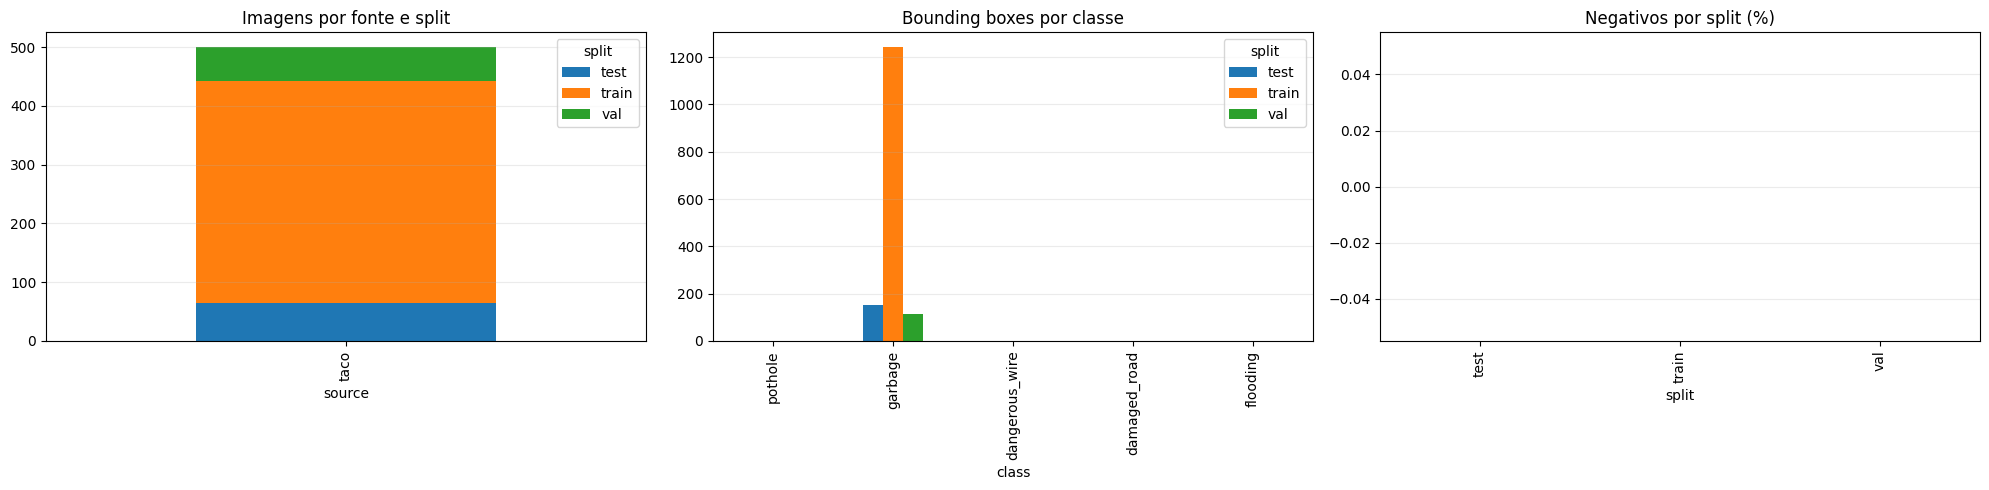

In [ ]:
# EDA: imagens por fonte/split, caixas por classe e negativos.
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

pd.crosstab(manifest.source, manifest.split).plot(kind="bar", stacked=True, ax=axes[0], title="Imagens por fonte e split")
coverage_pivot.reindex(VISH_CLASSES).fillna(0).plot(kind="bar", ax=axes[1], title="Bounding boxes por classe")
manifest.groupby("split").is_negative.mean().mul(100).plot(kind="bar", ax=axes[2], title="Negativos por split (%)")

for ax in axes:
    ax.grid(axis="y", alpha=.25)
plt.tight_layout()
plt.show()

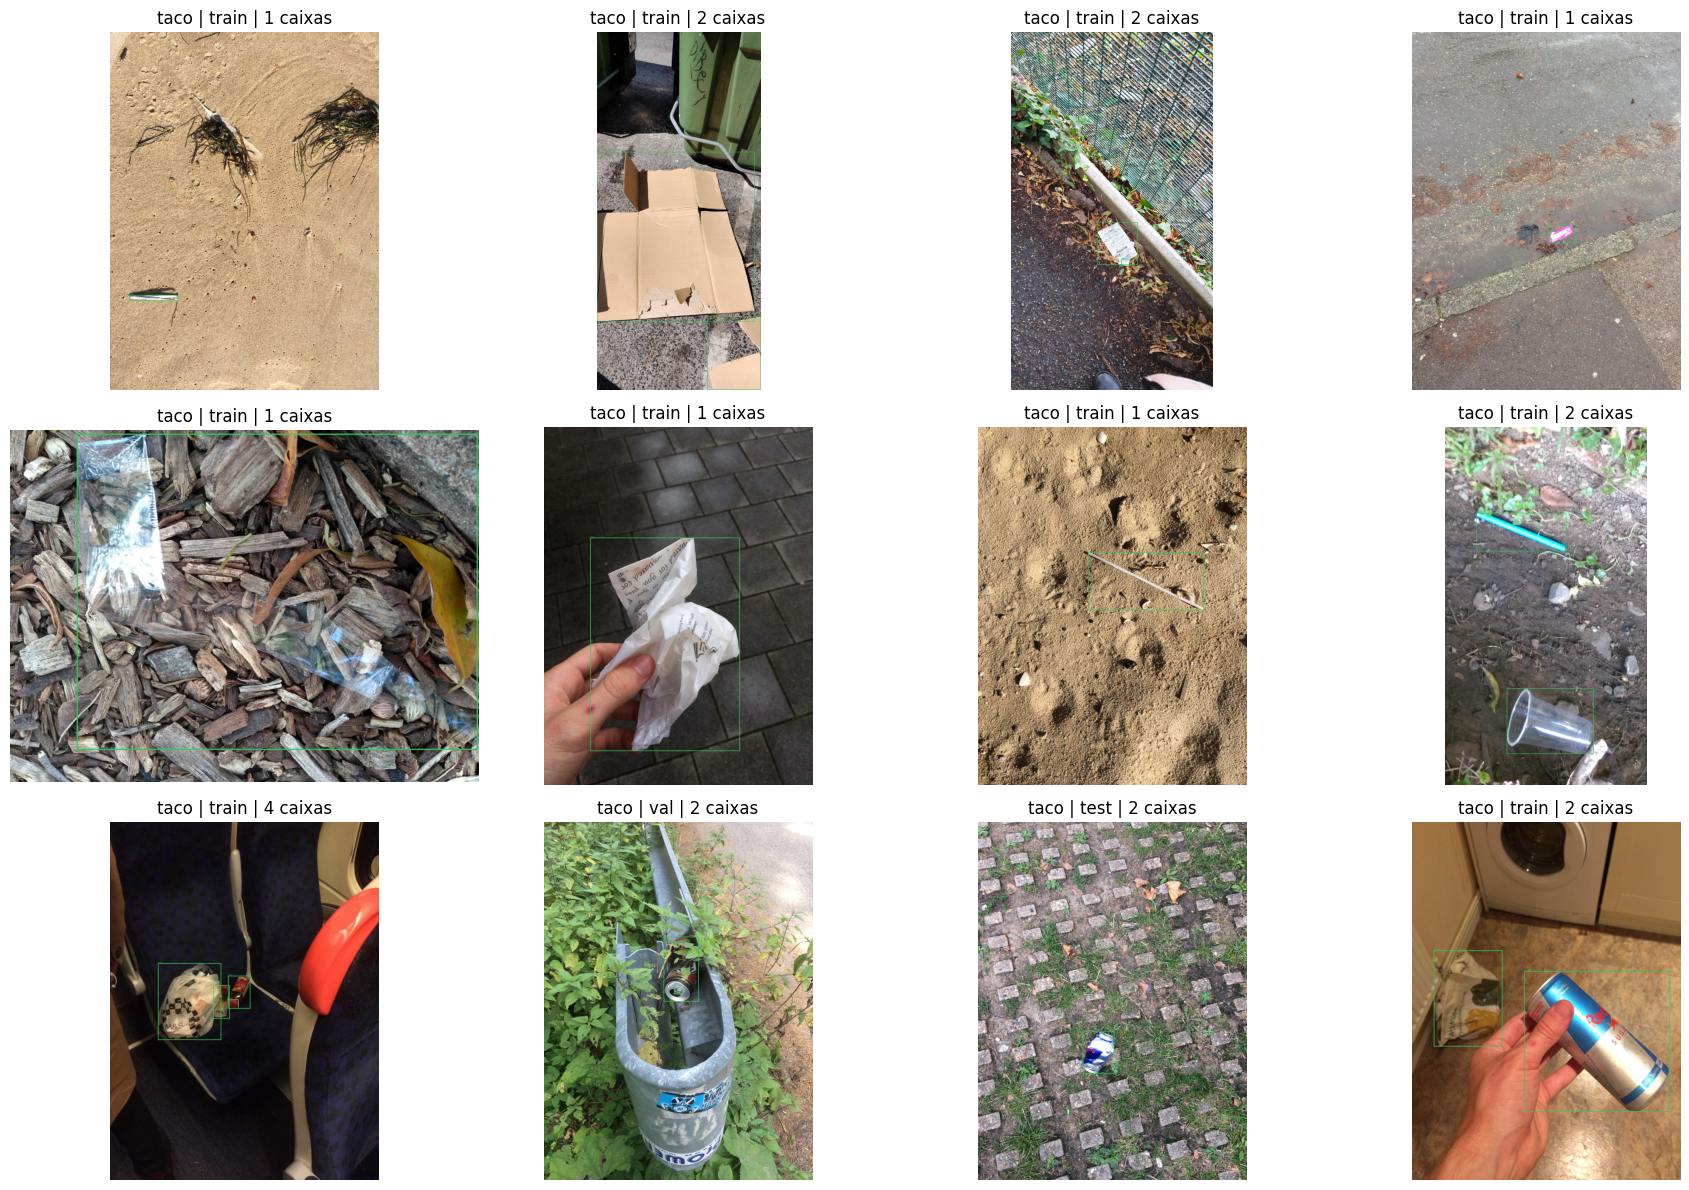

In [ ]:
def show_annotated(row, ax):
    image = Image.open(row.image_path).convert("RGB")
    draw = ImageDraw.Draw(image)
    w, h = image.size
    colors = ["#ff3b30", "#34c759", "#ff9500", "#007aff", "#af52de"]
    for line in Path(row.label_path).read_text().splitlines():
        cls, xc, yc, bw, bh = map(float, line.split())
        cls = int(cls)
        x1, y1 = (xc-bw/2)*w, (yc-bh/2)*h
        x2, y2 = (xc+bw/2)*w, (yc+bh/2)*h
        draw.rectangle([x1,y1,x2,y2], outline=colors[cls], width=max(2, w//350))
        draw.text((x1, max(0,y1-14)), ID_TO_CLASS[cls], fill=colors[cls])
    ax.imshow(image); ax.axis("off"); ax.set_title(f"{row.source} | {row.split} | {row.num_boxes} caixas")


# Inspeção aleatória obrigatória antes do treino.
sample = manifest.sample(min(12, len(manifest)), random_state=SEED)
fig, axes = plt.subplots(math.ceil(len(sample)/4), 4, figsize=(18, 4*math.ceil(len(sample)/4)))
axes = np.array(axes).reshape(-1)
for ax, row in zip(axes, sample.itertuples()):
    show_annotated(row, ax)
for ax in axes[len(sample):]: ax.axis("off")
plt.tight_layout(); plt.show()

## 7. Treinamento robusto

O modelo usa pesos COCO pré-treinados. Resolução 960 preserva melhor fios finos, pequenos resíduos e buracos distantes. Mosaic é encerrado nas últimas épocas para estabilizar a localização. A validação não deve ser usada para escolher exemplos manualmente; o teste brasileiro permanece intocado até o fim.

O notebook escolhe `yolo26m.pt` somente se houver memória de GPU suficiente. Em T4, `yolo26s.pt` é uma escolha mais segura e muito superior ao antigo `yolov8n.pt` para este experimento.

In [ ]:
if not torch.cuda.is_available():
    raise RuntimeError("GPU não disponível. Ative uma GPU no Colab.")

gpu_gb = torch.cuda.get_device_properties(0).total_memory / 2**30
BASE_MODEL = "yolo26m.pt" if gpu_gb >= 20 else "yolo26s.pt"
BATCH = -1  # Ultralytics usa automaticamente uma fração segura da memória.

TRAIN_NAME = f"vish_yolo26_{PROFILE}"
print("Modelo:", BASE_MODEL, "| imgsz:", IMG_SIZE, "| epochs:", EPOCHS)

Modelo: yolo26s.pt | imgsz: 640 | epochs: 10


In [ ]:
model = YOLO(BASE_MODEL)

train_results = model.train(
    data=str(VISH_YAML),
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH,
    device=0,
    workers=2,
    patience=20,
    seed=SEED,
    deterministic=True,
    optimizer="auto",
    cos_lr=True,
    mosaic=0.8,
    close_mosaic=10,
    mixup=0.0,
    degrees=3.0,
    translate=0.10,
    scale=0.50,
    perspective=0.0005,
    fliplr=0.5,
    hsv_h=0.015,
    hsv_s=0.50,
    hsv_v=0.40,
    project=str(RUNS_ROOT),
    name=TRAIN_NAME,
    exist_ok=True,
    plots=True,
    verbose=True,
)

Ultralytics 8.4.137 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/drive/MyDrive/Vish/v2/artifacts/vish_v2.yaml, degrees=3.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=0.8, multi_scale=0.0, name=vish_yolo2

In [ ]:
# Carrega explicitamente o melhor checkpoint, não o último.
BEST_PT = RUNS_ROOT / TRAIN_NAME / "weights" / "best.pt"
if not BEST_PT.exists():
    raise FileNotFoundError(BEST_PT)
best_model = YOLO(str(BEST_PT))
print("Melhor modelo:", BEST_PT)

Melhor modelo: /content/drive/MyDrive/Vish/v2/runs/vish_yolo26_smoke/weights/best.pt


In [ ]:
# Métricas no conjunto de validação.
val_metrics = best_model.val(data=str(VISH_YAML), split="val", imgsz=IMG_SIZE, device=0, plots=True)

per_class = pd.DataFrame({
    "class": VISH_CLASSES,
    "precision": np.asarray(val_metrics.box.p),
    "recall": np.asarray(val_metrics.box.r),
    "mAP50": np.asarray(val_metrics.box.ap50),
    "mAP50_95": np.asarray(val_metrics.box.maps),
})
display(per_class.style.format({c: "{:.3f}" for c in ["precision", "recall", "mAP50", "mAP50_95"]}))
per_class.to_csv(ARTIFACT_ROOT / "metrics_validation_per_class.csv", index=False)

print("mAP50 geral:", float(val_metrics.box.map50))
print("mAP50-95 geral:", float(val_metrics.box.map))

Ultralytics 8.4.137 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 122 layers, 9,467,115 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.4±0.1 ms, read: 397.9±203.3 MB/s, size: 1190.0 KB)
val: Scanning /content/drive/MyDrive/Vish/v2/dataset_yolo/labels/val.cache... 58 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 58/58 20.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.1s/it 4.6s
                   all         58        115      0.681        0.4      0.461      0.323
               garbage         58        115      0.681        0.4      0.461      0.323
Speed: 7.2ms preprocess, 20.9ms inference, 0.0ms loss, 0.6ms postprocess per image
Results saved to /content/runs/detect/val


ValueError: All arrays must be of the same length

In [ ]:
# Teste final. Idealmente inclui vish_br_test; rode uma única vez após congelar decisões.
test_images = list_images(UNIFIED_ROOT / "images" / "test")
if test_images:
    test_metrics = best_model.val(data=str(VISH_YAML), split="test", imgsz=IMG_SIZE, device=0, plots=True)
    test_per_class = pd.DataFrame({
        "class": VISH_CLASSES,
        "precision": np.asarray(test_metrics.box.p),
        "recall": np.asarray(test_metrics.box.r),
        "mAP50": np.asarray(test_metrics.box.ap50),
        "mAP50_95": np.asarray(test_metrics.box.maps),
    })
    display(test_per_class)
    test_per_class.to_csv(ARTIFACT_ROOT / "metrics_test_per_class.csv", index=False)
else:
    print("⚠️ Teste vazio. Adicione o Vish-BR-Test antes de reportar resultado final.")

In [ ]:
# Avaliação específica de falsos positivos em negativos difíceis.
negative_eval = manifest[(manifest.split.isin(["val", "test"])) & (manifest.is_negative)]
fp_rows = []
if len(negative_eval):
    preds = best_model.predict(
        source=negative_eval.image_path.tolist(),
        imgsz=IMG_SIZE, conf=0.25, device=0, verbose=False, stream=True,
    )
    for row, result in tqdm(zip(negative_eval.itertuples(), preds), total=len(negative_eval), desc="Hard negatives"):
        n = 0 if result.boxes is None else len(result.boxes)
        fp_rows.append({"file": row.file, "source": row.source, "false_detections_at_025": n})
    fp_df = pd.DataFrame(fp_rows)
    display(fp_df.groupby("source").false_detections_at_025.agg(["count", "sum", "mean"]))
    print("Taxa de imagens negativas com algum falso positivo:", f"{(fp_df.false_detections_at_025 > 0).mean():.1%}")
    fp_df.to_csv(ARTIFACT_ROOT / "hard_negative_false_positives.csv", index=False)
else:
    print("⚠️ Não há negativos em val/test; a taxa de falso positivo não pode ser medida.")

In [ ]:
# Curvas e matriz de confusão geradas pelo Ultralytics.
plot_dir = Path(val_metrics.save_dir)
plot_names = ["confusion_matrix_normalized.png", "PR_curve.png", "F1_curve.png", "P_curve.png", "R_curve.png", "results.png"]
available = [plot_dir / name for name in plot_names if (plot_dir / name).exists()]
if available:
    fig, axes = plt.subplots(math.ceil(len(available)/2), 2, figsize=(16, 7*math.ceil(len(available)/2)))
    axes = np.array(axes).reshape(-1)
    for ax, path in zip(axes, available):
        ax.imshow(Image.open(path)); ax.axis("off"); ax.set_title(path.name)
    for ax in axes[len(available):]: ax.axis("off")
    plt.tight_layout(); plt.show()

## 8. Limiar por classe

Um único `conf=0.25` é permissivo demais para o produto. Os valores abaixo são iniciais e devem ser ajustados usando as curvas Precision–Recall e o custo de cada erro. Para `dangerous_wire`, priorizamos precisão mais alta até termos mais dados próprios.

In [ ]:
CLASS_THRESHOLDS = {
    "pothole": 0.45,
    "garbage": 0.50,
    "dangerous_wire": 0.60,
    "damaged_road": 0.50,
    "flooding": 0.55,
}

threshold_df = pd.DataFrame({"class": list(CLASS_THRESHOLDS), "threshold": list(CLASS_THRESHOLDS.values())})
display(threshold_df)
threshold_df.to_csv(ARTIFACT_ROOT / "class_thresholds.csv", index=False)

In [ ]:
# Preserva o melhor modelo e um resumo reproduzível.
FINAL_PT = ARTIFACT_ROOT / "vish_yolo26_v2_best.pt"
shutil.copy2(BEST_PT, FINAL_PT)

experiment = {
    "profile": PROFILE,
    "base_model": BASE_MODEL,
    "epochs": EPOCHS,
    "img_size": IMG_SIZE,
    "seed": SEED,
    "classes": VISH_CLASSES,
    "images": int(len(manifest)),
    "sources": manifest.groupby("source").size().to_dict(),
    "thresholds": CLASS_THRESHOLDS,
    "best_model": str(FINAL_PT),
}
(ARTIFACT_ROOT / "experiment_summary.json").write_text(json.dumps(experiment, indent=2, ensure_ascii=False), encoding="utf-8")
print("Modelo final:", FINAL_PT)

## 9. Teste real com uma foto

Envie uma foto de celular. O modelo pode retornar vários problemas na mesma imagem. As detecções abaixo do limiar específico da classe são removidas e a tabela final mostra confiança e coordenadas.

In [ ]:
uploaded = files.upload()
if not uploaded:
    raise RuntimeError("Nenhuma foto enviada.")

photo_path = Path("/content") / next(iter(uploaded))
photo_path.write_bytes(next(iter(uploaded.values())))

minimum_conf = min(CLASS_THRESHOLDS.values())
result = best_model.predict(str(photo_path), imgsz=IMG_SIZE, conf=minimum_conf, device=0, verbose=False)[0]

image = Image.open(photo_path).convert("RGB")
draw = ImageDraw.Draw(image)
colors = ["#ff3b30", "#34c759", "#ff9500", "#007aff", "#af52de"]
detections = []

if result.boxes is not None:
    for xyxy, confidence, cls_id in zip(result.boxes.xyxy.cpu().numpy(), result.boxes.conf.cpu().numpy(), result.boxes.cls.cpu().numpy().astype(int)):
        name = ID_TO_CLASS[int(cls_id)]
        confidence = float(confidence)
        if confidence < CLASS_THRESHOLDS[name]:
            continue
        x1, y1, x2, y2 = map(float, xyxy)
        detections.append({"problema": name, "confianca": confidence, "x1": x1, "y1": y1, "x2": x2, "y2": y2})
        color = colors[int(cls_id)]
        width = max(3, image.width // 300)
        draw.rectangle([x1, y1, x2, y2], outline=color, width=width)
        draw.rectangle([x1, max(0, y1-24), min(image.width, x1+210), y1], fill=color)
        draw.text((x1+4, max(0, y1-21)), f"{name} {confidence:.1%}", fill="white")

plt.figure(figsize=(14, 10))
plt.imshow(image); plt.axis("off"); plt.title("Previsão Vish v2"); plt.show()

detection_df = pd.DataFrame(detections)
if len(detection_df):
    display(detection_df.style.format({"confianca": "{:.1%}", "x1": "{:.0f}", "y1": "{:.0f}", "x2": "{:.0f}", "y2": "{:.0f}"}))
else:
    print("Nenhum problema superou os limiares definidos.")

## 10. Como interpretar o resultado

- **Boa validação e teste BR fraco:** domain shift; colete mais imagens brasileiras.
- **Recall baixo em pothole:** aumente positivos variados e revise caixas pequenas/distantes; não apenas épocas.
- **Pessoas/carros viram problema:** acrescente essas cenas como hard negatives e faça hard-negative mining dos falsos positivos salvos.
- **Fios normais viram perigosos:** aumente negativos com postes/fiação normal e refine a definição de perigo.
- **Precision baixa e Recall alto:** suba o threshold da classe ou corrija rótulos ruidosos.
- **mAP muito alto com poucas fontes:** audite novamente duplicatas, sequências e origem geográfica.

### Critério sugerido antes de integrar ao Vish

Não use apenas mAP geral. Defina metas por classe no **Vish-BR-Test**, limite de falsos positivos em hard negatives e revisão humana para ocorrências elétricas. Um alerta de fio perigoso deve ser tratado como triagem, não como laudo técnico.

## 11. Referências principais

- Arya et al. **RDD2022: A multi-national image dataset for automatic road damage detection.** [Repositório oficial](https://github.com/sekilab/RoadDamageDetector) e [artigo](https://arxiv.org/abs/2209.08538).
- Passos et al. **Cracks and Potholes in Road Images.** [Mendeley Data, DOI 10.17632/t576ydh9v8.4](https://data.mendeley.com/datasets/t576ydh9v8/4).
- Mandhati et al. **pLitterStreet — Street Level Plastic Litter Detection Dataset.** [Zenodo, DOI 10.5281/zenodo.8288500](https://zenodo.org/records/8288500).
- Proença & Simões. **TACO: Trash Annotations in Context.** [GitHub oficial](https://github.com/pedropro/TACO) e [paper](https://arxiv.org/abs/2003.06975).
- Neto et al. **WasteInsight.** [Mendeley Data, DOI 10.17632/p8n7nbxyw3.1](https://data.mendeley.com/datasets/p8n7nbxyw3/1).
- Maske et al. **Urban Civic Issues / QR4Change.** [Mendeley Data, DOI 10.17632/zndzygc3p3.2](https://data.mendeley.com/datasets/zndzygc3p3/2).
- Oliveira, Buckeridge & Hirata. **Detecting tree and wire entanglements with deep learning.** [Código/dados](https://github.com/arturandre/tree-wires).
- Singha. **Flood Dataset-1.** [Mendeley Data, DOI 10.17632/px48m7vwvf.3](https://data.mendeley.com/datasets/px48m7vwvf/3).
- Ultralytics. **YOLO26 training documentation.** [Train mode](https://docs.ultralytics.com/modes/train/) e [YOLO26](https://docs.ultralytics.com/models/yolo26/).